# TargetWise demo

Log -> learn -> evaluate offline -> A/B -> go/no-go. Run all cells; the last one prints the launch report.

In [1]:
from dataclasses import replace
import io

from IPython.display import Image, Markdown, display

from targetwise.config import Config
from targetwise.pipeline import run_pipeline
from targetwise.plots import plot_estimated_vs_true
from targetwise.report import render_memo, render_report

def show(fig):
    buf = io.BytesIO()
    fig.savefig(buf, format='png', dpi=110, bbox_inches='tight')
    display(Image(buf.getvalue()))


cfg = replace(Config.from_env(), output_dir='reports')
res = run_pipeline(cfg, write=False)  # simulate logs, train 4 learners, OPE, budget, A/B, decision

## 1. Logged data is confounded
The naive treated-vs-untreated difference is biased; the true average uplift is tiny.

In [2]:
print(f"naive difference: {res['naive_ate']:+.3f}   true average uplift: {res['true_ate']:+.3f}")

naive difference: +0.999   true average uplift: +0.039


## 2. Offline estimates vs ground truth
Each dot is a policy. Left: estimate against the oracle value (on the dashed line = perfect). Right: the error with its 95% CI.

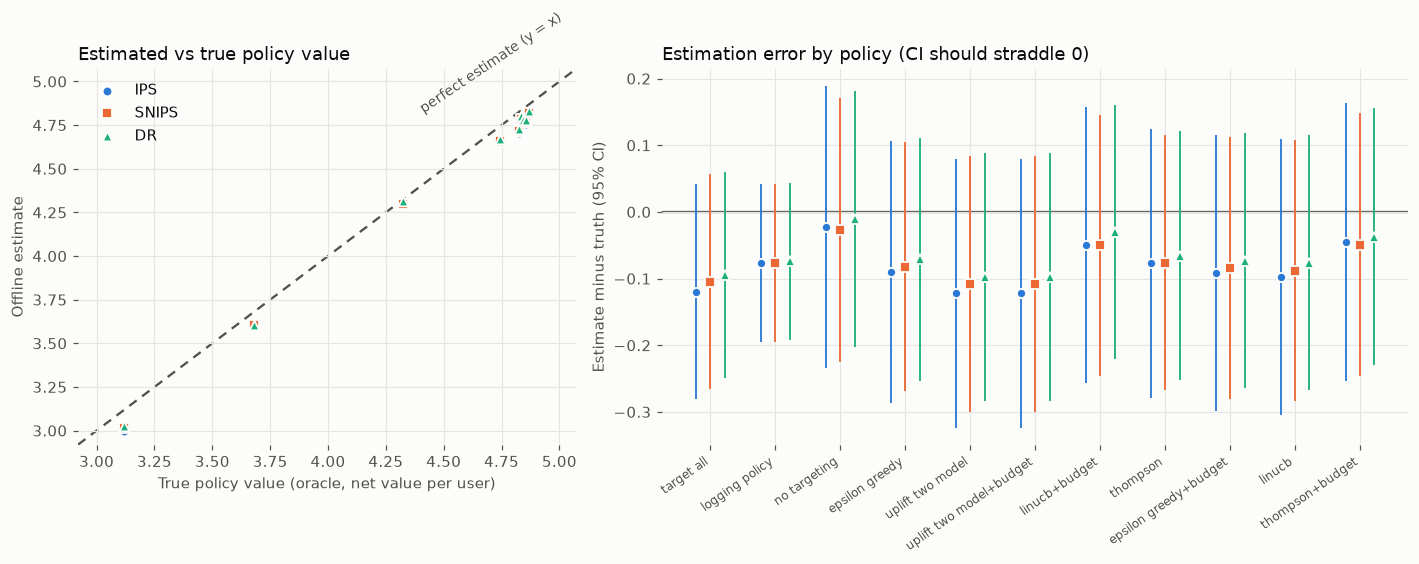

In [3]:
show(plot_estimated_vs_true(res))

## 3. Online learning regret
Cumulative pseudo-regret of the from-scratch bandits on a fresh stream.

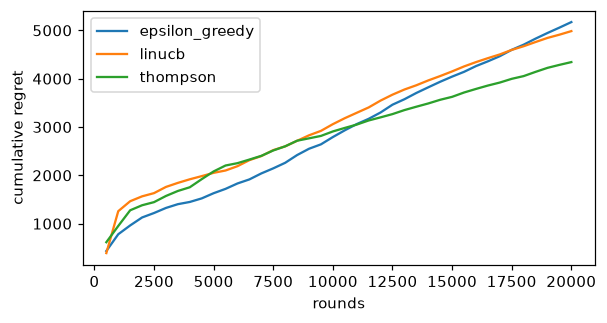

In [4]:
import pandas as pd
show(pd.DataFrame(res['online_regret'], index=[(i + 1) * 500 for i in range(len(res['online_regret']['linucb']))]).plot(
    xlabel='rounds', ylabel='cumulative regret', figsize=(6, 3)).figure)

## 4. Launch decision memo and go/no-go report

In [5]:
display(Markdown(render_memo(res)))

# Launch decision memo: audience targeting policy `thompson+budget`

**Decision: GO**. Launch to the full audience with the budget cap and a holdout for monitoring.

## Proposal
Replace the current targeting rule with a bandit-learned policy that targets users by expected incremental
revenue per unit cost, capped at 0.374 spend per user (30% of the cost of targeting everyone).

## Evidence
- **Offline (counterfactual, 30000 held-out logged users):** doubly robust lift over the current rule is
  +1.23 net value/user (95% CI +1.09 to +1.36); IPS and self-normalised IPS agree in sign and size.
  Versus not targeting at all: +0.52 (+0.38 to +0.66).
- **Randomised A/B test (4575 users per arm):** lift +1.09 (95% CI +0.65 to +1.54),
  one-sided p = 7.8e-07. Spend per user: 0.306 vs 0.654 for the current rule.
- **Power:** the test was sized for 0.61, half of the offline lift, at 80% power and alpha = 0.05; needed 4575 per arm.
- **Why trust the offline numbers:** the estimators were also scored against oracle policy values: see README

## Decision criteria
- PASS: OPE: DR lift CI excludes 0 (lift +1.2255 [+1.0887, +1.3624])
- PASS: OPE: IPS, SNIPS, DR all positive (IPS +1.2198, SNIPS +1.2158, DR +1.2255)
- PASS: A/B: one-sided lower bound > min lift (lift +1.0947, lower bound +0.7199, p=7.778e-07)
- PASS: A/B: sample size meets power plan (n/arm 4575 vs required 4575)
- PASS: Budget respected (spend/user 0.3064 vs budget 0.3744)

## Risks and mitigations
- **Selection optimism:** the candidate was picked as the best of four on the same log; the fresh-user A/B test is the unbiased confirmation.
- **Distribution shift:** the policy was learned from one logging period. Keep a randomised holdout and re-run offline evaluation monthly.
- **Overlap:** estimates are only valid where the old rule gave every user a non-trivial chance of each action (propensities in [0.1, 0.9]).
- **Simulation caveat:** these numbers come from a simulator with known truth, not production traffic.

## Next steps
1. Roll out to a small share of traffic with the budget cap enforced. 2. Monitor realised spend and lift against the interval above. 3. Re-train and re-evaluate on fresh logs before widening.


In [6]:
display(Markdown(render_report(res)))
print('DECISION:', res['decision'].verdict)

# TargetWise go/no-go report

## Decision: **GO**

Offline evaluation and the randomised test agree that the policy beats the control.

Candidate policy: `thompson+budget` vs control `logging_policy` (the current targeting rule).

| Criterion | Result | Detail |
|---|---|---|
| OPE: DR lift CI excludes 0 | PASS | lift +1.2255 [+1.0887, +1.3624] |
| OPE: IPS, SNIPS, DR all positive | PASS | IPS +1.2198, SNIPS +1.2158, DR +1.2255 |
| A/B: one-sided lower bound > min lift | PASS | lift +1.0947, lower bound +0.7199, p=7.778e-07 |
| A/B: sample size meets power plan | PASS | n/arm 4575 vs required 4575 |
| Budget respected | PASS | spend/user 0.3064 vs budget 0.3744 |

## Data

- Logged users: 30000 train / 30000 held-out evaluation (known, confounded logging policy)
- Naive treated-vs-untreated revenue difference: +0.999 (biased); true average uplift: +0.039
- Budget: 0.374 per user (30% of the cost of targeting everyone)

## Offline policy evaluation (net value per user, 95% CI)

| Policy | IPS | SNIPS | DR | True value (oracle) | Spend/user | ESS |
|---|---|---|---|---|---|---|
| no_targeting | +4.303 [+4.091, +4.515] | +4.299 [+4.100, +4.497] | +4.315 [+4.123, +4.507] | +4.326 | 0.000 | 12147 |
| target_all | +3.000 [+2.839, +3.162] | +3.015 [+2.854, +3.176] | +3.025 [+2.871, +3.179] | +3.120 | 1.250 | 14915 |
| logging_policy | +3.605 [+3.487, +3.724] | +3.605 [+3.487, +3.724] | +3.608 [+3.490, +3.725] | +3.682 | 0.653 | 30000 |
| epsilon_greedy | +4.652 [+4.456, +4.849] | +4.659 [+4.473, +4.846] | +4.671 [+4.489, +4.853] | +4.742 | 0.360 | 14123 |
| linucb | +4.759 [+4.552, +4.965] | +4.768 [+4.572, +4.965] | +4.780 [+4.589, +4.971] | +4.856 | 0.329 | 12771 |
| thompson | +4.767 [+4.565, +4.969] | +4.768 [+4.577, +4.960] | +4.779 [+4.592, +4.966] | +4.844 | 0.337 | 13430 |
| uplift_two_model | +4.705 [+4.503, +4.906] | +4.719 [+4.527, +4.910] | +4.729 [+4.543, +4.916] | +4.827 | 0.301 | 12996 |
| epsilon_greedy+budget | +4.763 [+4.557, +4.970] | +4.771 [+4.574, +4.967] | +4.782 [+4.591, +4.973] | +4.855 | 0.330 | 12779 |
| linucb+budget | +4.784 [+4.578, +4.990] | +4.784 [+4.588, +4.980] | +4.804 [+4.613, +4.995] | +4.834 | 0.372 | 12884 |
| thompson+budget | +4.825 [+4.617, +5.034] | +4.821 [+4.624, +5.018] | +4.833 [+4.641, +5.025] | +4.870 | 0.304 | 12794 |
| uplift_two_model+budget | +4.705 [+4.503, +4.906] | +4.719 [+4.527, +4.910] | +4.729 [+4.543, +4.916] | +4.827 | 0.301 | 12996 |

## Lift over the logging policy (paired, budget-constrained candidates)

| Candidate | IPS | SNIPS | DR |
|---|---|---|---|
| epsilon_greedy+budget | +1.158 [+1.005, +1.311] | +1.165 [+1.022, +1.308] | +1.174 [+1.038, +1.310] |
| linucb+budget | +1.179 [+1.028, +1.330] | +1.179 [+1.037, +1.320] | +1.196 [+1.061, +1.331] |
| thompson+budget | +1.220 [+1.066, +1.374] | +1.216 [+1.072, +1.360] | +1.226 [+1.089, +1.362] |
| uplift_two_model+budget | +1.099 [+0.952, +1.247] | +1.113 [+0.974, +1.252] | +1.121 [+0.990, +1.253] |

Winner's DR lift over *no targeting at all*: +0.518 [+0.379, +0.657]

## Power analysis

- Outcome sd (net value/user): 10.46; planned effect (haircut OPE lift): 0.6128
- Required n per arm for 80% power at alpha=0.05: 4575; used: 4575
- Analytic power at planned effect: 0.80; simulated power at the policy's true effect (n=4575, 100 runs): 1.00
- Minimum detectable effect at used n: 0.6127

## Simulated A/B test

| Arm | Mean net value/user | Spend/user |
|---|---|---|
| treatment | 4.8149 | 0.3064 |
| control | 3.7202 | 0.6536 |

Lift +1.0947 (SE 0.2279), 95% CI [+0.6481, +1.5413], one-sided p = 7.778e-07, n = 4575 per arm.

## Online learning regret (from-scratch bandits, cumulative pseudo-regret)

| Rounds | epsilon_greedy | linucb | thompson |
|---|---|---|---|
| 5000 | 1630 | 2052 | 2081 |
| 10000 | 2792 | 3059 | 2908 |
| 20000 | 5172 | 4985 | 4344 |


DECISION: GO
